# Lexical Retrieval Baselines (BoW, TF-IDF, BM25)

This notebook builds and evaluates three **lexical** retrieval baselines for our Bosnia and Herzegovina POI search engine. No embeddings are used; that comes in the next phase.

**What the notebook covers:**

1. **Data loading:** the cleaned POI table (`pois_clean.parquet`) and the development query set (`dev_queries.json`).
2. **NLP pipeline:** tokenization, custom stopwords and lemmatization.
3. **Three lexical representations:**
   - Bag-of-Words;
   - TF-IDF;
   - BM25.
4. **Retrieval and evaluation:**
   - spatial pre-filtering;
   - Hit Rate, Recall, Precision, MRR and NDCG, overall and per query type.
5. **Explainable AI:**
   - token-level score attribution;
   - global IDF inspection;
   - automated failure attribution.
6. **Conclusions** and motivation for the semantic phase.

> **Scope of the NLP pipeline.** All text processing (tokenization, stopword removal, lemmatization) is applied **only to the `nlp_text` column** and, at search time, to the **incoming query string**.
>
> The structured columns are never tokenized or modified:
> - `id`, `primary_name`, `primary_category`;
> - `lat`, `lon`, `city`, …
>
> They are used for three things:
> - **spatial filtering:** `lat`, `lon`;
> - **evaluation:** `id` is matched against `expected_ids`;
> - **display:** `primary_name`, `primary_category`.

### Setup

The libraries used and their roles:

| library | role |
|---|---|
| `pandas`, `numpy` | data handling, vectorized distance computation |
| `simplemma` | dictionary-based lemmatizer for Bosnian/Croatian/Serbian (`hbs`) and English |
| `scikit-learn` | `CountVectorizer` (BoW) and `TfidfVectorizer` (TF-IDF) |
| `rank_bm25` | `BM25Okapi` implementation |
| `matplotlib` | charts |

In [1]:
import json
import re
from functools import lru_cache
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import simplemma
from IPython.display import display
from rank_bm25 import BM25Okapi
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.preprocessing import normalize

pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 200)
DATA = Path("../data")

## 1. Data Loading & Inspection (`nlp_text`)

We load two inputs:

- **`pois_clean.parquet`**, the output of `data_cleaning_demo.ipynb`. We load only the columns we need: the structured metadata plus `nlp_text`. `nlp_text` is the single text field built during cleaning. For each POI it contains:
  - the name and aliases;
  - a bilingual category label (e.g. *pharmacy / apoteka*);
  - verbalized features (e.g. *outdoor seating / bašta*);
  - the address.
- **`dev_queries.json`**, the 50 development queries from `generate_eval_set.py`. Each query has:
  - a `type`;
  - the query text;
  - an optional location (`lat`, `lon`, `radius_km`);
  - the relevant POI ids (`expected_ids`).

We use only the **dev** split here. The test split stays untouched until the final evaluation, so that the design choices made in this notebook are not tuned on it.

In [2]:
POI_COLUMNS = ["id", "primary_name", "primary_category", "category_label", "lat", "lon", "city", "nlp_text"]
pois = pd.read_parquet(DATA / "processed" / "pois_clean.parquet", columns=POI_COLUMNS).reset_index(drop=True)
dev = json.loads((DATA / "eval" / "dev_queries.json").read_text(encoding="utf-8"))
dev_df = pd.DataFrame(dev)

print(f"POIs:        {pois.shape[0]:,} rows x {pois.shape[1]} columns")
print(f"Dev queries: {dev_df.shape[0]} rows x {dev_df.shape[1]} columns\n")
print("Query type distribution (dev):")
print(dev_df["type"].value_counts().to_string())
print(f"\nQueries with a location (lat/lon/radius): {dev_df['lat'].notna().sum()} / {len(dev_df)}")
print(f"Relevant ids per query: mean {dev_df['expected_ids'].map(len).mean():.2f}, "
      f"median {dev_df['expected_ids'].map(len).median():.0f}, max {dev_df['expected_ids'].map(len).max()}")

POIs:        44,149 rows x 8 columns
Dev queries: 50 rows x 7 columns

Query type distribution (dev):
type
entity              15
spatial_category    15
descriptive         12
cross_lingual        8

Queries with a location (lat/lon/radius): 15 / 50
Relevant ids per query: mean 5.80, median 2, max 30


**What we see:**

- **44,149 POIs** after deduplication. The dev split has **50 queries**: 15 entity, 15 spatial_category, 12 descriptive and 8 cross_lingual.
- **Only the 15 spatial queries come with coordinates.** All the others, including the descriptive queries that name a city (*"… u Sarajevu"*), must be ranked over the whole country. This becomes important in Section 4.
- **The ground-truth size varies a lot.** The median is 2 relevant POIs per query, but some spatial queries have up to 30. This is why we report both "at least one hit" metrics (Hit Rate, MRR) and "how many hits" metrics (Recall, NDCG).

Now we look at what the model will actually read: 5 random POIs with their identifying columns and the **raw** `nlp_text`, plus basic length statistics of the text field.

In [3]:
display(pois.sample(5, random_state=7)[["id", "primary_name", "primary_category", "nlp_text"]])

n_words = pois["nlp_text"].str.split().str.len()
print(f"nlp_text length in whitespace words: mean {n_words.mean():.1f}, median {n_words.median():.0f}, "
      f"95th pct {n_words.quantile(.95):.0f}, max {n_words.max()}")
print(f"POIs whose nlp_text mentions a city/town via the address: "
      f"{pois['nlp_text'].str.contains('address:', regex=False).mean():.1%}")

,id,primary_name,primary_category,nlp_text
25090,14072954559,NaN,memorial,memorial / spomen-obilježje
3701,611854573,Most Alije Izetbegovića,attraction,Most Alije Izetbegovića. tourist attraction / turistička atrakcija
43292,1805562543,Sačekaj,cafe,Sačekaj. cafe / kafić
3643,4092162097,Japanauto,car_parts,"Japanauto. car parts / auto dijelovi. brand: Hyundai, Suzuki, Nissan, Mitsubishi, Lexus. address: 24. juna..."
19431,9238167105,Stojna stijena,peak,Stojna stijena. peak / vrh. elevation 1443 m / nadmorska visina 1443 m


nlp_text length in whitespace words: mean 8.7, median 7, 95th pct 19, max 98
POIs whose nlp_text mentions a city/town via the address: 19.5%


**Observations about `nlp_text`:**

- **The documents are very short:** a median of 7 words, and 95% have at most 19. Many POIs have no name at all. For example, *"memorial / spomen-obilježje"* is the entire document.

  For lexical models this means:
  - term frequency is almost always 1;
  - document-length normalization (BM25's $b$) matters less than in typical text retrieval.
- **The text is bilingual by construction:** *"cafe / kafić"*, *"peak / vrh"*. This bridges English and Bosnian queries at the category level, but not for features expressed in only one form.
- **The city is often missing.** Only ~20% of POIs mention a city or town, and only through `address:`. A query like *"kafić u Mostaru"* therefore cannot be matched on *Mostar* for ~80% of the correct cafés.

## 2. NLP Pipeline on `nlp_text`

The same three-step pipeline is applied to every POI's `nlp_text` (once, at indexing time) and to every query (at search time):

```
raw text ──► tokenize ──► remove custom stopwords ──► lemmatize ──► (stopwords again) ──► tokens
```

Using the **identical** function on both sides is essential for lexical retrieval. A word only matches if the document and the query end up producing exactly the same token.

### 2.1 Tokenizer

The tokenizer is a single regular expression, `[^\W_]+`. It matches any run of Unicode letters or digits, so:

- **diacritics are preserved:** `č, ć, ž, š, đ` are letters, so *kafić* stays *kafić*. It does not become *kafi* + *c*.
- **numbers are preserved:**
  - *benzin 95* keeps `95`;
  - *OŠ 1* keeps `1`.
  These numbers often distinguish otherwise identical names.
- **Cyrillic is preserved** as Cyrillic. We deliberately do **not** transliterate here; Section 4 shows what this costs.
- punctuation, quotes and slashes become separators.

Before matching, the text is lowercased. We also join `wi-fi` → `wifi`; otherwise every *Wi-Fi* mention would produce two meaningless tokens, `wi` and `fi`, which were among the 50 most frequent tokens in the corpus.

In [4]:
import unicodedata

# same script/Unicode normalization that data_cleaning_demo.ipynb applies to every field of nlp_text
CYR = dict(zip("абвгдђежзијклљмнњопрстћуфхцчџш",
               ["a", "b", "v", "g", "d", "đ", "e", "ž", "z", "i", "j", "k", "l", "lj", "m",
                "n", "nj", "o", "p", "r", "s", "t", "ć", "u", "f", "h", "c", "č", "dž", "š"]))
CYR2LAT = dict(CYR)
CYR2LAT.update({"й": "j", "ы": "y", "э": "e", "ю": "ju", "я": "ja", "щ": "šč", "ъ": "", "ь": "", "ё": "jo",
                "і": "i", "ї": "ji", "є": "je", "ѓ": "đ", "ќ": "ć", "ѕ": "dz"})
CYR2LAT.update({c.upper(): l[:1].upper() + l[1:] for c, l in list(CYR2LAT.items()) if l})

def translit(s):
    return "".join(CYR2LAT.get(ch, ch) for ch in s)

def is_cyr(ch):
    return "Ѐ" <= ch <= "ӿ"

def is_lat(ch):
    return ch.isalpha() and "LATIN" in unicodedata.name(ch, "")

CYR_LOOKALIKE = dict(zip("аеорсухкмтјіѕАВЕКМНОРСТХЈІЅ", "aeopcyxkmtjisABEKMHOPCTXJIS"))
LAT_LOOKALIKE = {l: c for c, l in CYR_LOOKALIKE.items() if c not in "уіѕІЅ"}

def _fix_word(m):
    w = m.group(0)
    n_cyr, n_lat = sum(map(is_cyr, w)), sum(map(is_lat, w))
    if not (n_cyr and n_lat):
        return w
    if n_lat >= n_cyr:
        return "".join(CYR_LOOKALIKE.get(ch, ch) for ch in w)
    return "".join(LAT_LOOKALIKE.get(ch, ch) for ch in w)

QUOTES = str.maketrans({"„": '"', "“": '"', "”": '"', "«": '"', "»": '"', "″": '"', "‘": "'", "’": "'", "`": "'"})

def tidy(s):
    s = unicodedata.normalize("NFC", s).replace("Ð", "Đ").replace("ð", "đ")
    s = re.sub(r"\w+", _fix_word, s).translate(QUOTES).replace("''", '"')
    return re.sub(r"\s+", " ", s).strip(" ;,")

TOKEN_RE = re.compile(r"[^\W_]+")

def tokenize(text: str) -> list[str]:
    text = text.lower().replace("wi-fi", "wifi")
    return TOKEN_RE.findall(text)

example = "Kafić „Manja“. cafe / kafić. outdoor seating / bašta, Wi-Fi / WiFi, fuel: petrol 95. Ђурђевак"
print(tokenize(example))

['kafić', 'manja', 'cafe', 'kafić', 'outdoor', 'seating', 'bašta', 'wifi', 'wifi', 'fuel', 'petrol', '95', 'ђурђевак']


The output shows the tokenizer behaving as intended:

- **Diacritics are intact:** `kafić`, `bašta`.
- **Numbers are kept:** `95`.
- **`Wi-Fi` became one token**, `wifi`.
- **Cyrillic stays Cyrillic:** `ђурђевак`.
- **Quotes and slashes are gone.**

Stopwords have not been removed yet, which is why the repeated *kafić* is still there.

### 2.2 Custom stopword list

Generic stopword lists are a bad fit for our data, for two reasons:

1. **They remove words we need.** Standard lists drop short prepositions such as *u*, *na*, *kod*, *near* and *by*. In a **geographic** search engine these words carry intent: *"kafić **kod** Katedrale"*, *"hotel **u** Mostaru"*, *"parking **near** the airport"*. We therefore keep a set of spatial and temporal prepositions and adverbs (`PRESERVE`) that can never be removed.
2. **They miss the real noise in `nlp_text`.** The noise in our text is specific to our pipeline. The list was informed by the token frequency analysis and the cleaning notebook, and has four parts:
   - **Template labels** produced by the verbalization step in `data_cleaning_demo.ipynb`:
     - `address`;
     - `operator`;
     - `brand`;
     - `also known as`;
     - the unit `m` (from *elevation: 1200 m*);
     - `bb` (*bez broja*, "no house number").
     These labels appear in thousands of POIs and say nothing about the place.
   - **Legal-form residue:** `doo`, `dd`, and `d`, `o` from *d.o.o.*
   - **BHS function words:** *i, je, se, za, sa, ili, …*
   - **Query filler:** *gdje, tražim, mogu, naći, adresa, …* These are words a user types around the actual need.
   - **English function words:** *the, of, and, is, …*

Single-character tokens are also dropped, except digits and preserved words such as *u*. These are mostly initials or residue (*S. Kranjčevića* → `s`).

In [5]:
# spatial and temporal prepositions/adverbs: never removed, even if they look like stopwords
PRESERVE = {
    # BHS spatial
    "u", "na", "kod", "pored", "blizu", "iza", "ispred", "iznad", "ispod", "uz", "do", "od",
    "između", "preko", "oko", "pokraj", "nasuprot", "unutar", "van",
    # BHS temporal
    "prije", "poslije", "tokom", "nakon",
    # English spatial / temporal
    "in", "on", "at", "near", "by", "around", "before", "after", "next", "behind", "opposite",
}

STOP_BHS = {
    "i", "a", "ali", "ili", "pa", "te", "je", "su", "se", "sam", "si", "smo", "ste", "bi", "biti", "da",
    "ne", "ni", "li", "što", "sto", "šta", "sta", "koji", "koja", "koje", "kojem", "to", "ta", "taj",
    "ovo", "ovaj", "ova", "ove", "za", "sa", "s", "iz", "o", "po", "pri", "kroz", "ga", "mu", "ih", "im",
    "me", "mi", "ti", "on", "ona", "ono", "oni", "njegov", "njihov",
    "ja", "mene", "meni", "mnom", "nas", "nama",   # 'blizu mene' -> lemma 'ja' must not reach the index
    # query filler
    "gdje", "kako", "kada", "kad", "tražim", "tražiti", "trebam", "trebati", "želim", "želiti",
    "mogu", "moći", "naći", "pronaći", "ima", "imati", "neki", "neka", "neko", "molim", "adresa",
}
STOP_EN = {
    "a", "an", "the", "and", "or", "of", "for", "with", "is", "are", "be", "to", "from", "as", "this",
    "that", "it", "its", "i", "me", "my", "we", "you", "where", "what", "which", "find", "looking",
    "want", "any", "some", "please", "there",
}
# noise specific to our nlp_text (template labels and legal-form residue from data cleaning)
STOP_TEMPLATE = {"address", "operator", "brand", "also", "known", "m", "bb"}
STOP_NOISE = {"doo", "dd", "d", "o", "fi", "wi"}

STOPWORDS = (STOP_BHS | STOP_EN | STOP_TEMPLATE | STOP_NOISE) - PRESERVE

def remove_stopwords(tokens: list[str]) -> list[str]:
    return [t for t in tokens
            if t in PRESERVE or (t not in STOPWORDS and (len(t) > 1 or t.isdigit()))]

print(f"Stopwords: {len(STOPWORDS)}  (BHS {len(STOP_BHS)}, EN {len(STOP_EN)}, "
      f"template {len(STOP_TEMPLATE)}, noise {len(STOP_NOISE)})")
print(f"\nPreserved geospatial/temporal words ({len(PRESERVE)}):")
print(", ".join(sorted(PRESERVE)))
print(f"\nPreserved words that would have been stopwords in a generic list: "
      f"{sorted(PRESERVE & {'u', 'na', 'do', 'od', 'oko', 'preko', 'in', 'on', 'at', 'by', 'before', 'after'})}")
print(f"Overlap PRESERVE ∩ STOPWORDS (must be empty): {PRESERVE & STOPWORDS}")
print("\nDemo:", remove_stopwords(tokenize("Gdje je kafić sa baštom u blizini, near the old bridge?")))

Stopwords: 122  (BHS 82, EN 33, template 7, noise 6)

Preserved geospatial/temporal words (34):
after, around, at, before, behind, blizu, by, do, in, ispod, ispred, iza, između, iznad, kod, na, nakon, nasuprot, near, next, od, oko, on, opposite, pokraj, pored, poslije, preko, prije, tokom, u, unutar, uz, van

Preserved words that would have been stopwords in a generic list: ['after', 'at', 'before', 'by', 'do', 'in', 'na', 'od', 'oko', 'on', 'preko', 'u']
Overlap PRESERVE ∩ STOPWORDS (must be empty): set()

Demo: ['kafić', 'baštom', 'u', 'blizini', 'near', 'old', 'bridge']


**Results of the stopword step:**

- **Preserved words.** 34 words are protected. 12 of them (*u, na, do, od, in, on, at, by, …*) would have been removed by a typical generic stopword list.
- **The overlap check is empty,** so no preserved word can be dropped by mistake.
- **The demo query.** *"Gdje je kafić sa baštom u blizini, near the old bridge?"* loses its filler (*gdje, je, sa, the*) but keeps both location markers, ***u*** and ***near***.

*baštom* is still inflected at this point; that is the lemmatizer's job.

### 2.3 Lemmatization with `simplemma`

BHS is highly inflected. The same pharmacy can appear as *apoteka, apoteke, apoteci, apoteku, apotekom*. Without normalization, a query *"apoteku u centru"* would not match a document containing *apoteka*.

A **lemmatizer** maps each form to its dictionary form (the lemma). We use `simplemma`, a lightweight dictionary-based lemmatizer, with languages `("hbs", "en")`:

- **`hbs`** is simplemma's code for the shared Serbo-Croatian dictionary, which covers Bosnian, Croatian and Serbian. In simplemma 2.x there is no separate `hr` code; `hbs` replaces it.
- **`en`** handles the English half of our bilingual labels and English queries: *museums → museum*, *bakeries → bakery*.

Three implementation details:

- **Caching.** Results are cached with `lru_cache`. The corpus has ~25k distinct tokens but hundreds of thousands of occurrences, so caching makes lemmatizing the whole corpus take seconds.
- **No lemmatization for some tokens.** Digits and preserved prepositions are kept exactly as they are.
- **A small correction table.** Dictionary lemmatizers sometimes lemmatize a word that is *already* in its base form into a different word. We found two such errors on very frequent corpus words:
  - *pekara* (bakery) → *pekar* (baker);
  - *luka* (port, and the city *Banja **Luka***) → *luk* (onion).

  Both are corrected in `LEMMA_FIX`. We deliberately keep this table minimal, and we built it from the **corpus side**, not from the dev queries, so it does not tune the system to the evaluation set.

Stopwords are applied a second time **after** lemmatization. This catches query filler that only becomes a stopword in its lemma form, e.g. *tražim → tražiti*.

In [6]:
LEMMA_LANGS = ("hbs", "en")
LEMMA_FIX = {"pekara": "pekara", "luka": "luka", "banjoj": "banja", "kafiću": "kafić"}   # base forms that simplemma maps to a different word

@lru_cache(maxsize=None)
def lemmatize_token(tok: str) -> str:
    if tok in LEMMA_FIX:
        return LEMMA_FIX[tok]
    if tok.isdigit() or tok in PRESERVE:
        return tok
    return simplemma.lemmatize(tok, lang=LEMMA_LANGS).lower()

def preprocess(text: str) -> list[str]:
    # the single pipeline used for BOTH nlp_text and incoming queries
    tokens = remove_stopwords(tokenize(translit(tidy(text))))   # tidy + translit: as in nlp_text
    return remove_stopwords([lemmatize_token(t) for t in tokens])

for w in ["apoteke", "apoteci", "apoteku", "crkve", "džamije", "baštom", "pekaru", "pekara",
          "luka", "luci", "museums", "bakeries", "tražim", "u", "95"]:
    print(f"{w:>10} -> {lemmatize_token(w)}")

for q in ["апотека у Бањој Луци", "kafiću u Mostaru"]:
    print(f"{q!r} -> {preprocess(q)}")

   apoteke -> apoteka
   apoteci -> apoteka
   apoteku -> apoteka
     crkve -> crkva
   džamije -> džamija
    baštom -> bašta
    pekaru -> pekara
    pekara -> pekara
      luka -> luka
      luci -> luka
   museums -> museum
  bakeries -> bakery
    tražim -> tražiti
         u -> u
        95 -> 95
'апотека у Бањој Луци' -> ['apoteka', 'u', 'banja', 'luka']
'kafiću u Mostaru' -> ['kafić', 'u', 'mostar']


**What the lemmatizer does:**

- **BHS inflection is normalized:** *apoteke / apoteci / apoteku → apoteka*, *baštom → bašta*, *džamije → džamija*.
- **English plurals are normalized:** *museums → museum*, *bakeries → bakery*.
- **The two corrections work:** *pekara* and *luka* stay as they are instead of becoming *pekar* (baker) and *luk* (onion). *luci* (the locative in *Banjoj Luci*) now correctly maps to *luka*.
- ***tražim → tražiti*** is the kind of case the second stopword pass removes.

**Known gaps** (visible later in the failure analysis):

- simplemma does not know some instrumental forms such as *internetom*, *bežičnim* and *dizelom*. These stay unlemmatized and cannot match *internet*.
- *najbliži* is lemmatized to *blizak*, which no POI contains.

Now we run the pipeline over all 44k `nlp_text` values. The result is stored in two **new** columns:

- `tokens`: the list used by BM25;
- `lemmatized_text`: the same tokens joined by spaces, used by the scikit-learn vectorizers.

`nlp_text` itself and all structured columns stay unchanged.

In [7]:
pois["tokens"] = pois["nlp_text"].map(preprocess)
pois["lemmatized_text"] = pois["tokens"].str.join(" ")

raw_tok = pois["nlp_text"].map(tokenize)
print(f"Tokens per POI: raw {raw_tok.str.len().mean():.1f} -> processed {pois['tokens'].str.len().mean():.1f}")
print(f"Distinct terms: raw {len(set().union(*raw_tok)):,} -> processed {len(set().union(*pois['tokens'])):,}")
print(f"POIs with an empty token list: {(pois['tokens'].str.len() == 0).sum()}")

sample = pois.sample(5, random_state=11)
before_after = pd.DataFrame({
    "primary_name": sample["primary_name"],
    "raw nlp_text": sample["nlp_text"],
    "tokens (after custom stopwords)": sample["nlp_text"].map(lambda s: " ".join(remove_stopwords(tokenize(s)))),
    "lemmatized_text": sample["lemmatized_text"],
})
display(before_after)

Tokens per POI: raw 7.5 -> processed 6.7
Distinct terms: raw 24,698 -> processed 22,470
POIs with an empty token list: 0


,primary_name,raw nlp_text,tokens (after custom stopwords),lemmatized_text
19182,Grič,Grič. peak / vrh. elevation 1149 m / nadmorska visina 1149 m. Planina Kruščica,grič peak vrh elevation 1149 nadmorska visina 1149 planina kruščica,grič peak vrh elevation 1149 nadmorska visina 1149 planina kruščica
2268,Dobrun,"Dobrun. tourist attraction / turistička atrakcija, railway station / željeznička stanica, transit station ...",dobrun tourist attraction turistička atrakcija railway station željeznička stanica transit station stanica...,dobrun tourist attraction turistički atrakcija railway station željeznički stanica transit station stanica...
19553,Strmica,Strmica. peak / vrh. elevation 990 m / nadmorska visina 990 m,strmica peak vrh elevation 990 nadmorska visina 990,strmica peak vrh elevation 990 nadmorska visina 990
3696,Spomenik ubijenoj djeci opkoljenog Sarajeva 1992-1995,"Spomenik ubijenoj djeci opkoljenog Sarajeva 1992-1995. fountain, memorial / spomen-obilježje. sculpture / ...",spomenik ubijenoj djeci opkoljenog sarajeva 1992 1995 fountain memorial spomen obilježje sculpture skulptu...,spomenik ubijenoj djeca opkoljenog sarajevo 1992 1995 fountain memorial spomen obilježje sculpture skulptu...
43884,NaN,bank / banka,bank banka,bank banka


**Effect on the whole corpus:**

- **Fewer tokens:** 7.5 → 6.7 per POI on average. Most of the removed tokens are template labels (*address, also known as*).
- **Smaller vocabulary:** 24.7k → 22.5k distinct terms. Inflected forms collapse together, and noise such as *wi*, *fi* and *doo* disappears.
- **No POI ends up empty,** so every POI is still retrievable.

The before/after table shows the three stages side by side:

- **Normalization:** *Sarajeva → sarajevo*, *djeci → djeca*, *turistička → turistički*.
- **Untouched words:** proper names and numbers (*Grič*, *1149*, *1992*).
- **Unrecognized forms:** some rarer inflections (*ubijenoj*, *opkoljenog*) are not in the dictionary and stay as they are. That is acceptable, since they are rarely query words.

## 3. Lexical Representations (Three Retrieval Versions)

All three models are built on the **same** processed tokens. The only difference between them is how a document–query match is **weighted**.

| model | document representation | score |
|---|---|---|
| **BoW** | raw term counts $\text{tf}(t,d)$, unigrams + bigrams | cosine similarity |
| **TF-IDF** | $\text{tf}(t,d)\cdot\text{idf}(t)$, unigrams + bigrams, L2-normalized | cosine similarity |
| **BM25** | term-frequency saturation + document-length normalization, unigrams | BM25 sum |

**Cosine similarity.** For BoW and TF-IDF, the score is

$$\cos(\mathbf{q},\mathbf{d}) = \frac{\mathbf{q}\cdot\mathbf{d}}{\lVert\mathbf{q}\rVert\,\lVert\mathbf{d}\rVert} = \sum_i \hat q_i\,\hat d_i ,$$

where the hats denote L2-normalized vectors.

**The scikit-learn IDF** (smoothed) is

$$\text{idf}(t) = \ln\frac{1+N}{1+\text{df}(t)} + 1$$

It rewards rare, discriminative terms (a POI name like *kaiser*) and down-weights frequent ones (*vrh*, *peak*).

**BM25 (Okapi)** scores a document $d$ for a query $q$ as

$$\text{BM25}(q,d)=\sum_{t\in q}\text{idf}(t)\cdot\frac{\text{tf}(t,d)\,(k_1+1)}{\text{tf}(t,d)+k_1\left(1-b+b\,\frac{|d|}{\text{avgdl}}\right)},\qquad k_1=1.5,\ b=0.75$$

Two properties distinguish it from TF-IDF:

- **$k_1$ saturates term frequency.** A word repeated five times is not five times as important.
- **$b$ normalizes for document length.** A match in a short description counts more than the same match in a long one.

**Settings and the role of bigrams:**

- `min_df=2` drops terms that occur in only one POI. That removes typos and one-off tokens and keeps the vocabulary compact.
- Bigrams (`ngram_range=(1, 2)`) let BoW and TF-IDF capture multi-word units such as *benzinska pumpa* or *banja luka*. BM25, as specified, works on the unigram lemma lists.

**Tokenizing the vectorizers.** The scikit-learn vectorizers receive our already-processed `lemmatized_text`. They split on whitespace only (`tokenizer=str.split`), so they reuse our pipeline exactly. This matters because the default scikit-learn token pattern would silently drop one-letter tokens such as the preserved *u*.

In [8]:
VEC_ARGS = dict(tokenizer=str.split, token_pattern=None, lowercase=False, ngram_range=(1, 2), min_df=2)

bow = CountVectorizer(**VEC_ARGS)
X_bow = normalize(bow.fit_transform(pois["lemmatized_text"]))   # L2 rows: dot product = cosine

tfidf = TfidfVectorizer(**VEC_ARGS)                                # L2-normalized by default
X_tfidf = tfidf.fit_transform(pois["lemmatized_text"])

bm25 = BM25Okapi(pois["tokens"].tolist())                          # k1=1.5, b=0.75

for name, vec, X in [("BoW", bow, X_bow), ("TF-IDF", tfidf, X_tfidf)]:
    vocab = vec.get_feature_names_out()
    n_bi = sum(" " in v for v in vocab)
    print(f"{name:7} vocabulary: {len(vocab):,} terms ({len(vocab) - n_bi:,} unigrams, {n_bi:,} bigrams) | "
          f"matrix {X.shape[0]:,} x {X.shape[1]:,}, density {X.nnz / (X.shape[0] * X.shape[1]):.5%}")
print(f"BM25    corpus: {bm25.corpus_size:,} documents, {len(bm25.idf):,} unigram terms, "
      f"avg document length {bm25.avgdl:.2f} tokens")

BoW     vocabulary: 26,972 terms (9,795 unigrams, 17,177 bigrams) | matrix 44,149 x 26,972, density 0.03729%
TF-IDF  vocabulary: 26,972 terms (9,795 unigrams, 17,177 bigrams) | matrix 44,149 x 26,972, density 0.03729%
BM25    corpus: 44,149 documents, 22,470 unigram terms, avg document length 6.66 tokens


**What was built:**

- **The sparse vocabulary (BoW and TF-IDF):** ~27k terms, of which almost two-thirds are bigrams.
  - Density is about 0.04%: an average POI has only ~10 non-zero entries out of 27k.
  - Sparse matrices are therefore essential. Scoring all 44k POIs takes a few milliseconds per query.
- **BM25:** works on 22.5k unigram terms, with an average document length of only **6.7 tokens**.
- **The difference between the term counts:** `min_df=2` dropped roughly half of the unigrams, because many POI names are unique. BM25 keeps them all, which helps exact entity matches on rare names.

## 4. Baseline Retrieval & IR Evaluation on `dev_queries.json`

### 4.1 Unified search function

`search()` is the one entry point for all three models:

1. **Preprocess the query** with the exact same `preprocess()` used for `nlp_text`.
2. **Score** every POI with the chosen model (sparse matrix–vector product for BoW/TF-IDF, `get_scores` for BM25).
3. **Spatial pre-filter.** If the query has `lat`, `lon` and `radius_km`, only POIs within `radius_km` are kept. Distances use the vectorized **Haversine** formula on the structured `lat`/`lon` columns:

   $$d = 2R\arcsin\sqrt{\sin^2\tfrac{\Delta\varphi}{2}+\cos\varphi_1\cos\varphi_2\sin^2\tfrac{\Delta\lambda}{2}},\qquad R = 6371\text{ km}$$

   Queries without coordinates are ranked over all POIs.
4. **Rank.** Only POIs with a **positive** score are returned, i.e. those sharing at least one term with the query, sorted by score.

   Returning zero-score POIs would be a random ordering, not retrieval. Ties keep the original row order (`kind="stable"`), so results are deterministic.

In [9]:
LAT, LON, IDS = pois["lat"].to_numpy(), pois["lon"].to_numpy(), pois["id"].to_numpy()
MODELS = ["BoW", "TF-IDF", "BM25"]

def haversine_km(lat, lon):
    p1, p2 = np.radians(lat), np.radians(LAT)
    dphi, dlmb = p2 - p1, np.radians(LON - lon)
    a = np.sin(dphi / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(dlmb / 2) ** 2
    return 2 * 6371.0 * np.arcsin(np.sqrt(a))

def score_all(model: str, q_tokens: list[str]) -> np.ndarray:
    if model == "BoW":
        return (X_bow @ normalize(bow.transform([" ".join(q_tokens)])).T).toarray().ravel()
    if model == "TF-IDF":
        return (X_tfidf @ tfidf.transform([" ".join(q_tokens)]).T).toarray().ravel()
    if model == "BM25":
        return bm25.get_scores(q_tokens)
    raise ValueError(model)

def search(query: str, model: str, lat=None, lon=None, radius_km=None, k=None):
    # returns row positions of the ranked POIs and their scores
    q_tokens = preprocess(query)
    scores = score_all(model, q_tokens)
    mask = scores > 0
    if lat is not None and lon is not None and radius_km is not None:
        mask &= haversine_km(lat, lon) <= radius_km
    cand = np.flatnonzero(mask)
    order = cand[np.argsort(-scores[cand], kind="stable")]
    return (order[:k], scores[order[:k]]) if k else (order, scores[order])

q = dev[0]
print(f"Query: {q['query']!r} -> tokens {preprocess(q['query'])}\n")
for m in MODELS:
    pos, sc = search(q["query"], m, q["lat"], q["lon"], q["radius_km"], k=3)
    print(m, [(pois.at[p, "primary_name"], round(float(s), 3)) for p, s in zip(pos, sc)])

Query: 'flower u Mostaru' -> tokens ['flower', 'u', 'mostar']

BoW [('Sveučilište u Mostaru: Studij kineziologije', 0.6), ('Županijski sud u Mostaru', 0.522), ('Sveučilište u Mostaru', 0.417)]
TF-IDF [('Sveučilište u Mostaru: Studij kineziologije', 0.477), ('Županijski sud u Mostaru', 0.429), ('Simplement Toi Flower designer', 0.403)]
BM25 [('Županijski sud u Mostaru', 11.625), ('Sveučilište u Mostaru: Studij kineziologije', 11.625), ('Flower shop', 10.958)]


The first dev query already shows the core weakness of lexical matching.

The user wants the *Flower Bar* in Mostar. The tokens are `flower`, `u`, `mostar`.

- **BoW and TF-IDF** put institutions whose *names* contain **"u Mostaru"** first: a university, a court.
- **BM25** ranks a courthouse first. The correct *Flower Bar* is not in the top 3 of any model. TF-IDF and BM25 find it at rank 4; BoW only at rank 70.

Section 5 explains exactly why, term by term.

### 4.2 Evaluation metrics

Notation:
- $R$ is the set of relevant POIs (`expected_ids`);
- $r_1, r_2, \dots$ is the ranked list returned by the system;
- $\text{rel}_i = 1$ if $r_i \in R$, else $0$.

We use binary relevance. Every metric is computed per query and then averaged over queries (macro-average).

| metric | formula | what it answers |
|---|---|---|
| **Hit Rate@K** | $\text{Hit@}K = \mathbb{1}\left[\,\exists\, i \le K: \text{rel}_i = 1\,\right]$ | Did the user see *at least one* correct POI in the top K? |
| **Recall@K** | $\text{Recall@}K = \dfrac{\lvert \{r_1..r_K\} \cap R\rvert}{\lvert R\rvert}$ | Which share of *all* correct POIs is in the top K? |
| **Precision@5** | $\text{P@}5 = \dfrac{\lvert \{r_1..r_5\} \cap R\rvert}{5}$ | How clean is the first screen of results? |
| **MRR** | $\text{MRR} = \dfrac{1}{\lvert Q\rvert}\sum_{q} \dfrac{1}{\text{rank}_q}$ | How high is the *first* correct POI? (0 if none is returned) |
| **NDCG@K** | $\text{NDCG@}K = \dfrac{\text{DCG@}K}{\text{IDCG@}K}$ | Are correct POIs placed near the top, given how many exist? |

with

$$\text{DCG@}K=\sum_{i=1}^{K}\frac{\text{rel}_i}{\log_2(i+1)}, \qquad \text{IDCG@}K=\sum_{i=1}^{\min(\lvert R\rvert,K)}\frac{1}{\log_2(i+1)}$$

**Notes on interpretation:**

- **Recall@K has a ceiling below 1** when $|R| > K$. A spatial query with 20 correct pharmacies can reach at most Recall@10 = 0.5. NDCG is normalized with IDCG, so it reaches 1 whenever the top K are all relevant.
- **Precision@5 has a ceiling** of $|R|/5$ when $|R| < 5$. Entity queries usually have one correct POI, so their P@5 is at most 0.2.
- **Pick metrics per query type.** Hit Rate and MRR are the natural metrics for **entity** queries. Recall, Precision and NDCG matter more for **spatial** and **descriptive** queries, which have several correct answers.

The metrics are implemented from scratch below. A toy example with known answers checks them before we use them.

In [10]:
def hit_at_k(ranked, rel, k):
    return float(any(r in rel for r in ranked[:k]))

def recall_at_k(ranked, rel, k):
    return len(set(ranked[:k]) & rel) / len(rel)

def precision_at_k(ranked, rel, k):
    return len(set(ranked[:k]) & rel) / k

def reciprocal_rank(ranked, rel):
    for i, r in enumerate(ranked, start=1):
        if r in rel:
            return 1.0 / i
    return 0.0

def ndcg_at_k(ranked, rel, k):
    dcg = sum(1.0 / np.log2(i + 1) for i, r in enumerate(ranked[:k], start=1) if r in rel)
    idcg = sum(1.0 / np.log2(i + 1) for i in range(1, min(len(rel), k) + 1))
    return dcg / idcg

# toy check: relevant {B, D}; system ranks A, B, C, D, E
ranked, rel = ["A", "B", "C", "D", "E"], {"B", "D"}
toy = {
    "Hit@5": hit_at_k(ranked, rel, 5), "Recall@5": recall_at_k(ranked, rel, 5),
    "P@5": precision_at_k(ranked, rel, 5), "RR": reciprocal_rank(ranked, rel),
    "NDCG@5": ndcg_at_k(ranked, rel, 5),
}
expected_ndcg = (1 / np.log2(3) + 1 / np.log2(5)) / (1 + 1 / np.log2(3))
assert toy == {"Hit@5": 1.0, "Recall@5": 1.0, "P@5": 0.4, "RR": 0.5, "NDCG@5": expected_ndcg}
print({k: round(v, 4) for k, v in toy.items()}, "-> all checks passed")

{'Hit@5': 1.0, 'Recall@5': 1.0, 'P@5': 0.4, 'RR': 0.5, 'NDCG@5': np.float64(0.6509)} -> all checks passed


All five metric functions give the hand-computed values on the toy ranking.

Take NDCG@5 = 0.651. The two relevant items sit at ranks 2 and 4 instead of the ideal ranks 1 and 2, so

$$\text{NDCG@5} = \frac{1/\log_2 3 + 1/\log_2 5}{1 + 1/\log_2 3} = 0.651$$

We can now trust the numbers below.

### 4.3 Running the evaluation

Each of the 50 dev queries is run through each of the 3 models, giving 150 runs. Each run uses the query's own spatial constraint if it has one.

Besides the metrics, we store diagnostics for later analysis:
- the number of candidates returned;
- the rank of the first relevant POI.

In [11]:
METRICS = ["Hit@5", "Hit@10", "Recall@5", "Recall@10", "P@5", "MRR", "NDCG@5", "NDCG@10"]

rows, runs = [], {}
for q in dev:
    rel = set(q["expected_ids"])
    for m in MODELS:
        pos, _ = search(q["query"], m, q["lat"], q["lon"], q["radius_km"])
        ranked = IDS[pos].tolist()
        runs[(q["query_id"], m)] = pos
        rr = reciprocal_rank(ranked, rel)
        rows.append({
            "query_id": q["query_id"], "type": q["type"], "model": m, "query": q["query"],
            "Hit@5": hit_at_k(ranked, rel, 5), "Hit@10": hit_at_k(ranked, rel, 10),
            "Recall@5": recall_at_k(ranked, rel, 5), "Recall@10": recall_at_k(ranked, rel, 10),
            "P@5": precision_at_k(ranked, rel, 5), "MRR": rr,
            "NDCG@5": ndcg_at_k(ranked, rel, 5), "NDCG@10": ndcg_at_k(ranked, rel, 10),
            "first_rel_rank": round(1 / rr) if rr else None, "n_returned": len(ranked), "n_relevant": len(rel),
        })
res = pd.DataFrame(rows)
res["model"] = pd.Categorical(res["model"], MODELS, ordered=True)

overall = res.groupby("model", observed=True)[METRICS].mean()
print("Overall (dev, 50 queries) - macro-averaged")
display(overall.style.format("{:.3f}").highlight_max(axis=0, props="font-weight:bold; background-color:#d4edda"))

Overall (dev, 50 queries) - macro-averaged


,Hit@5,Hit@10,Recall@5,Recall@10,P@5,MRR,NDCG@5,NDCG@10
model,,,,,,,,
BoW,0.400,0.460,0.270,0.393,0.268,0.361,0.352,0.378
TF-IDF,0.480,0.500,0.350,0.432,0.268,0.406,0.400,0.413
BM25,0.600,0.620,0.448,0.532,0.292,0.550,0.515,0.528


**Overall, BM25 is the strongest baseline on every metric, and BoW is the weakest:**

| | BoW | TF-IDF | BM25 |
|---|---|---|---|
| Hit@5 | 0.40 | 0.46 | **0.54** |
| MRR | 0.36 | 0.39 | **0.49** |
| NDCG@10 | 0.37 | 0.39 | **0.47** |

**Why the ordering BoW < TF-IDF < BM25:**

- **IDF lets rare, informative terms dominate.** A rare name like *kaiser* outweighs common terms like *kafić* or *vrh*. BoW gives every term the same weight.
- **BM25 adds term-frequency saturation.** A POI that repeats *džamija* three times in its name and aliases does not get three times the score.

**But the absolute level is low:** even BM25 shows a correct POI in the top 5 for only about half of the queries. P@5 is ~0.27 for all models. Part of that is the metric's ceiling (entity queries with one answer can reach at most 0.2), but most of it is real failure.

The per-type breakdown shows where the failures are.

### 4.4 Breakdown by query type

The overall averages hide very different behaviour per query type (see `generate_eval_set.py`):

- **entity:** one named place;
- **spatial_category:** a category within a radius;
- **descriptive:** a category plus attributes in a named city;
- **cross_lingual:** English or Cyrillic.

In [12]:
TYPE_ORDER = ["entity", "spatial_category", "descriptive", "cross_lingual"]
by_type = res.groupby(["type", "model"], observed=True)[METRICS].mean().reindex(TYPE_ORDER, level=0)
display(by_type.style.format("{:.3f}"))

print("\nDiagnostics per type (BM25):")
diag = (res[res["model"] == "BM25"].groupby("type")
        .agg(queries=("query_id", "size"), relevant_per_query=("n_relevant", "mean"),
             returned_median=("n_returned", "median"), no_relevant_returned=("first_rel_rank", lambda s: s.isna().sum()))
        .reindex(TYPE_ORDER))
display(diag.round(1))


Diagnostics per type (BM25):


,queries,relevant_per_query,returned_median,no_relevant_returned
type,,,,
entity,15,1.1,48.0,1
spatial_category,15,12.3,11.0,2
descriptive,12,2.6,2703.5,0
cross_lingual,8,7.2,1312.5,0


**The breakdown shows four very different situations:**

1. **entity: the lexical models' home ground.**
   - BM25 reaches **Hit@5 = 0.87** and MRR = 0.71, far ahead of TF-IDF (0.67) and BoW (0.40).
   - Entity queries contain a rare proper name, and BM25's IDF weighting rewards exactly that.
2. **spatial_category: solved mostly by the spatial filter, not by the text model.**
   - All three models have Hit@5 = 0.87.
   - Once the candidates are restricted to a 1–2 km radius, a single category word (*apoteka*) is enough.
   - **BoW is slightly *better* than TF-IDF and BM25 here** (P@5 0.79 vs 0.71). Section 5.4 explains why.
   - The two failures (*frizer*) are vocabulary gaps, not ranking problems.
3. **descriptive: near-total failure** (Hit@5 ≤ 0.08), for three reasons:
   - the city is only in the text and is missing from most `nlp_text`;
   - features are phrased differently (*bežičnim internetom* vs *WiFi*);
   - the median query returns **2,696** candidates. Every café in the country matches *kafić*, so the few correct ones drown.
4. **cross_lingual: zero for TF-IDF and BM25.**
   - Cyrillic queries share no tokens with the Latin index.
   - The English queries mostly fail on the city (*Zenica*, *Bihać*), not on the category.

### 4.5 Visual comparison

The grouped bar charts show five key metrics for the three models, overall (left) and for each query type.

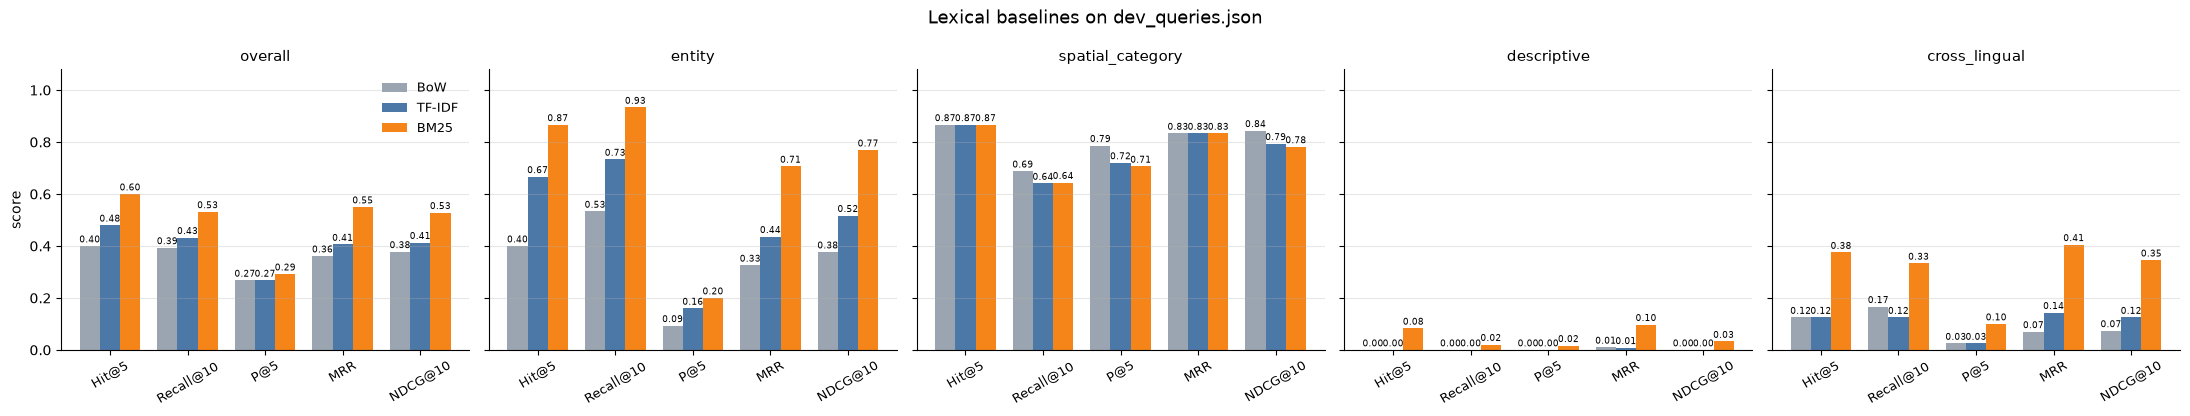

In [13]:
KEY = ["Hit@5", "Recall@10", "P@5", "MRR", "NDCG@10"]
COLORS = {"BoW": "#9aa5b1", "TF-IDF": "#4c78a8", "BM25": "#f58518"}

panels = [("overall", overall)] + [(t, by_type.loc[t]) for t in TYPE_ORDER]
fig, axes = plt.subplots(1, len(panels), figsize=(22, 4.2), sharey=True)
x, w = np.arange(len(KEY)), 0.26
for ax, (title, tbl) in zip(axes, panels):
    for j, m in enumerate(MODELS):
        vals = tbl.loc[m, KEY].to_numpy(dtype=float)
        bars = ax.bar(x + (j - 1) * w, vals, w, label=m, color=COLORS[m])
        ax.bar_label(bars, fmt="%.2f", fontsize=6.5, padding=1)
    ax.set_xticks(x, KEY, rotation=30, fontsize=9)
    ax.set_title(title, fontsize=11)
    ax.set_ylim(0, 1.08)
    ax.grid(axis="y", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("score")
axes[0].legend(frameon=False, fontsize=9)
fig.suptitle("Lexical baselines on dev_queries.json", fontsize=13)
plt.tight_layout()
plt.show()

**The chart in one sentence:** lexical retrieval is good when the query contains a **rare exact string** (entity) or when a **spatial filter** does the hard work (spatial_category). It collapses as soon as the query describes the need in words the document does not literally contain (descriptive, cross_lingual).

This split is the main motivation for the semantic phase.

## 5. Explainable AI (XAI) & Interpretability Analysis

Lexical models are **white-box**: every score is an explicit sum over the terms the query and document share. That means we can say exactly *why* a POI was ranked first. This is the reference point for the semantic phase, where scores come from opaque dense vectors.

### 5.1 Local token-level score attribution

For a query $q$ and the top-1 document $d$:

**TF-IDF.** With L2-normalized vectors, the cosine score decomposes exactly into per-term products:

$$\cos(\mathbf q,\mathbf d) = \sum_{t} \hat q_t\,\hat d_t, \qquad \text{contribution}(t) = \frac{\hat q_t\,\hat d_t}{\sum_{t'} \hat q_{t'}\,\hat d_{t'}}\times 100\%$$

The terms $t$ include bigrams.

**BM25.** The score is already a sum, so each query term contributes

$$\text{idf}(t)\cdot\frac{\text{tf}(t,d)(k_1+1)}{\text{tf}(t,d)+k_1(1-b+b\,|d|/\text{avgdl})}$$

We recompute these terms by hand and **assert** that they add up to the library's score, so the explanation is guaranteed to be exact.

We explain three dev queries, one each of the entity, spatial and descriptive types.

In [14]:
FEATURES = tfidf.get_feature_names_out()

def explain_tfidf(query: str, doc_pos: int) -> pd.DataFrame:
    qv = tfidf.transform([" ".join(preprocess(query))])
    prod = qv.multiply(X_tfidf[doc_pos]).tocoo()
    out = pd.DataFrame({"term": FEATURES[prod.col],
                        "q_i": qv[0, prod.col].toarray().ravel(),
                        "d_i": X_tfidf[doc_pos, prod.col].toarray().ravel(),
                        "contribution": prod.data})
    out["pct"] = 100 * out["contribution"] / out["contribution"].sum()
    return out.sort_values("contribution", ascending=False, ignore_index=True)

def explain_bm25(query: str, doc_pos: int) -> pd.DataFrame:
    q_tokens = preprocess(query)
    freqs, dl = bm25.doc_freqs[doc_pos], bm25.doc_len[doc_pos]
    norm = bm25.k1 * (1 - bm25.b + bm25.b * dl / bm25.avgdl)
    rows = []
    for t in dict.fromkeys(q_tokens):                       # unique, in query order
        tf, idf = freqs.get(t, 0), bm25.idf.get(t, 0.0)
        part = idf * tf * (bm25.k1 + 1) / (tf + norm) if tf else 0.0
        rows.append({"term": t, "q_count": q_tokens.count(t), "tf": tf, "idf": idf,
                     "score": part * q_tokens.count(t)})     # get_scores counts repeated query terms
    out = pd.DataFrame(rows)
    assert np.isclose(out["score"].sum(), bm25.get_scores(q_tokens)[doc_pos]), "BM25 decomposition mismatch"
    return out.sort_values("score", ascending=False, ignore_index=True)

XAI_IDS = [next(q["query_id"] for q in dev if q["type"] == t) for t in ["entity", "spatial_category", "descriptive"]]
DEV_BY_ID = {q["query_id"]: q for q in dev}
XAI_IDS

['dev-ent-01', 'dev-spa-01', 'dev-des-01']

**Which queries we explain:** the first query of each type:

- `dev-ent-01`: *flower u Mostaru*;
- `dev-spa-01`: *džamija blizu mene*;
- `dev-des-01`: *bar u Sarajevu sa bežičnim internetom i sa klimom*.

These are fixed by position, not hand-picked to look good or bad.

For each of the three queries, the code below does four things:
1. finds the top-1 POI of TF-IDF and of BM25;
2. marks whether that POI is relevant (✓ or ✗);
3. prints the per-term table;
4. plots the attribution as horizontal bars.

Terms that the query contains but the document does not have contribute **0**. They are listed as well, because they show *what the model could not match*.

dev-ent-01 [entity]  query: 'flower u Mostaru'  ->  tokens ['flower', 'u', 'mostar']

TF-IDF top-1: 'Sveučilište u Mostaru: Studij kineziologije' (university), score 0.477, ✗ not relevant
  nlp_text: 'Sveučilište u Mostaru: Studij kineziologije. university / fakultet. operator: Sveučilište u Mostaru'


,term,q_i,d_i,contribution,pct
0,u mostar,0.6057,0.4648,0.2816,59.0498
1,u,0.3742,0.2871,0.1074,22.5291
2,mostar,0.3383,0.2596,0.0878,18.4211



BM25 top-1: 'Županijski sud u Mostaru' (courthouse), score 11.625, ✗ not relevant
  nlp_text: 'Županijski sud u Mostaru. courthouse / sud. also known as: Kantonalni sud u Mostaru'


,term,q_count,tf,idf,score
0,u,1,2,5.017,6.171
1,mostar,1,2,4.435,5.454
2,flower,1,0,8.990,0.000


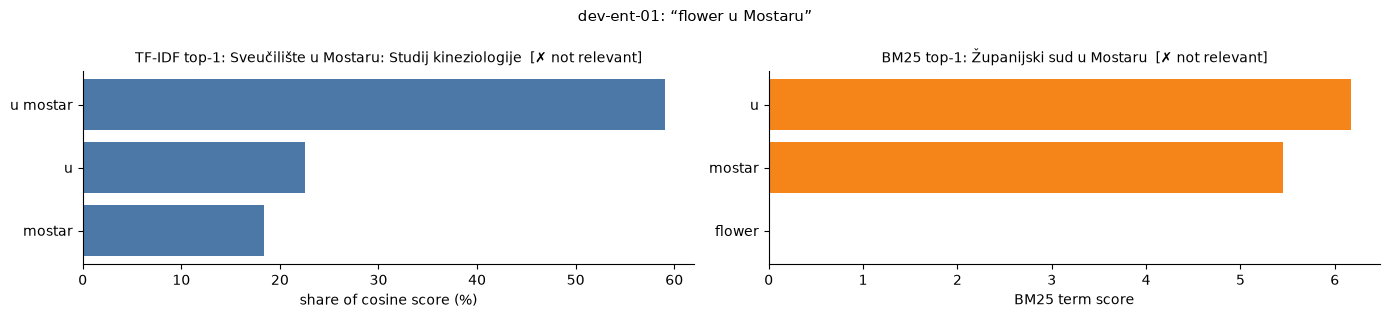

dev-spa-01 [spatial_category]  query: 'džamija blizu mene'  ->  tokens ['džamija', 'blizu']

TF-IDF top-1: 'Arnaudija' (place_of_worship), score 0.606, ✓ relevant
  nlp_text: 'Arnaudija. mosque / džamija. also known as: Džamija Hasana defterdara; Defterdarija džamija'


,term,q_i,d_i,contribution,pct
0,džamija,1.0,0.6063,0.6063,100.0



BM25 top-1: 'Arnaudija' (place_of_worship), score 5.447, ✓ relevant
  nlp_text: 'Arnaudija. mosque / džamija. also known as: Džamija Hasana defterdara; Defterdarija džamija'


,term,q_count,tf,idf,score
0,džamija,1,3,3.433,5.447
1,blizu,1,0,0.000,0.000


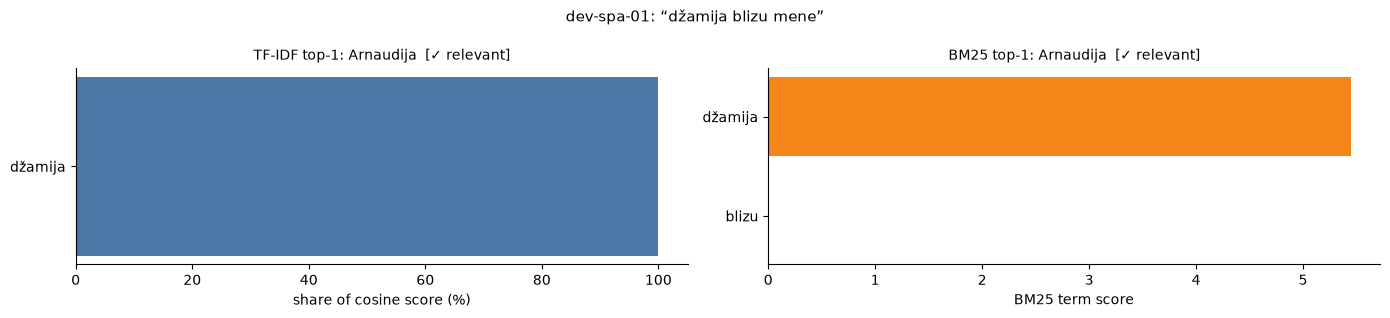

dev-des-01 [descriptive]  query: 'bar u Sarajevu sa bežičnim internetom i sa klimom'  ->  tokens ['bar', 'u', 'sarajevo', 'bežičnim', 'internetom', 'klima']

TF-IDF top-1: 'Kampus Univerziteta u Sarajevu' (university), score 0.479, ✗ not relevant
  nlp_text: 'Kampus Univerziteta u Sarajevu. university / fakultet, barracks. also known as: Kampus Sveučilišta u Sarajevu; University of Sarajevo Campus'


,term,q_i,d_i,contribution,pct
0,u sarajevo,0.5987,0.3882,0.2324,48.4927
1,sarajevo,0.3433,0.3711,0.1274,26.5812
2,u,0.4292,0.2783,0.1195,24.9261



BM25 top-1: 'Kantonalni sud u Sarajevu' (courthouse), score 10.595, ✗ not relevant
  nlp_text: 'Kantonalni sud u Sarajevu. courthouse / sud. also known as: Županijski sud u Sarajevu. address: Šenoina 1, Sarajevo'


,term,q_count,tf,idf,score
0,u,1,2,5.017,5.486
1,sarajevo,1,3,3.795,5.108
2,bar,1,0,4.021,0.000
3,bežičnim,1,0,0.000,0.000
4,internetom,1,0,0.000,0.000
5,klima,1,0,5.436,0.000


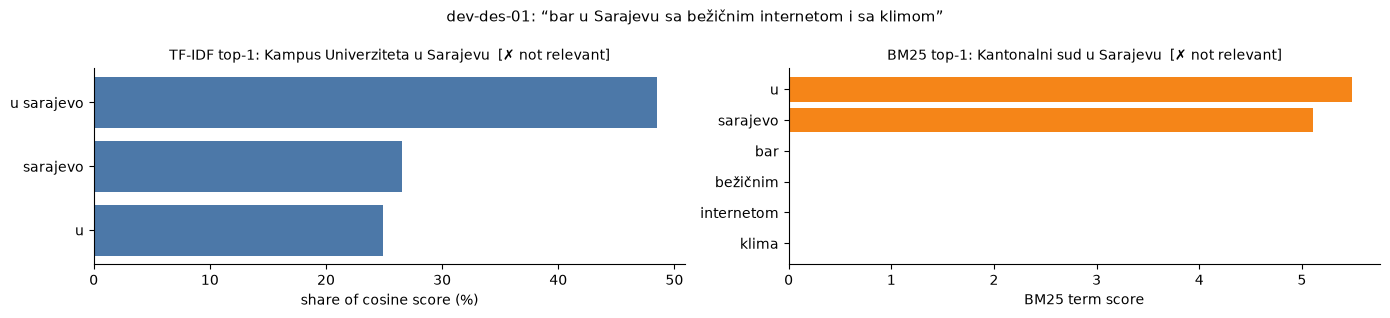

In [15]:
for qid in XAI_IDS:
    q = DEV_BY_ID[qid]
    rel = set(q["expected_ids"])
    print("=" * 110)
    print(f"{qid} [{q['type']}]  query: {q['query']!r}  ->  tokens {preprocess(q['query'])}")
    fig, axes = plt.subplots(1, 2, figsize=(14, 3.2))
    for ax, model in zip(axes, ["TF-IDF", "BM25"]):
        pos, sc = search(q["query"], model, q["lat"], q["lon"], q["radius_km"], k=1)
        if len(pos) == 0:
            ax.set_axis_off(); ax.set_title(f"{model}: no result"); continue
        p = pos[0]
        mark = "✓ relevant" if IDS[p] in rel else "✗ not relevant"
        print(f"\n{model} top-1: {pois.at[p, 'primary_name']!r} ({pois.at[p, 'primary_category']}), "
              f"score {sc[0]:.3f}, {mark}\n  nlp_text: {pois.at[p, 'nlp_text'][:140]!r}")
        if model == "TF-IDF":
            e = explain_tfidf(q["query"], p)
            display(e.round(4))
            vals, labels, xlabel = e["pct"], e["term"], "share of cosine score (%)"
        else:
            e = explain_bm25(q["query"], p)
            display(e.round(3))
            vals, labels, xlabel = e["score"], e["term"], "BM25 term score"
        ax.barh(labels[::-1], vals[::-1], color=COLORS[model])
        ax.set_xlabel(xlabel)
        ax.set_title(f"{model} top-1: {pois.at[p, 'primary_name'] or '(unnamed)'}  [{mark}]", fontsize=10)
        ax.spines[["top", "right"]].set_visible(False)
    fig.suptitle(f"{qid}: “{q['query']}”", fontsize=11)
    plt.tight_layout()
    plt.show()

**What the attributions reveal:**

- **`dev-ent-01` (failure).**
  - **TF-IDF:** the top-1 POI is a university. **59%** of its score comes from the bigram `u mostar` and **23%** from `u` alone. The actual name, `flower`, does not appear in that document at all.
  - **BM25:** ranks a courthouse first. `u` (6.2) contributes more than `mostar` (5.5), because *u* occurs twice in *"Županijski sud **u** Mostaru … Kantonalni sud **u** Mostaru"*.
  - **Takeaway:** the model behaved exactly as designed, and the design is wrong for this query. The location phrase outweighed the name.
- **`dev-spa-01` (success).**
  - *mene* is now correctly removed as a stopword.
  - **100%** of the TF-IDF score comes from `džamija`. `blizu` contributes 0, because no POI contains it.
  - The spatial filter did the rest, and the top-1 (*Arnaudija* mosque) is relevant.
- **`dev-des-01` (failure).**
  - `bežičnim` and `internetom` contribute **0**: they are unlemmatized inflected forms that never occur in `nlp_text`, which says *WiFi*.
  - `bar` and `klima` would match the right POI. But `u sarajevo` (48%) plus `sarajevo` and `u` make a university and a court score higher than any bar.

**Why this matters:** without opening a single model internal, we can point to the exact tokens that caused each error. This level of transparency will be much harder to get with dense embeddings.

### 5.2 Global vocabulary / IDF inspection

Local explanations show single decisions. The IDF table shows what the model values **globally**:

- **Lowest IDF (most common terms).** These are what the model treats as nearly worthless. If stopwords had leaked into the index, words like *the*, *i* or *address* would appear here.
- **Highest IDF (most discriminative terms).** These are rare, distinctive terms, typically parts of proper names. Many terms share the maximum IDF, because they all occur in exactly `min_df = 2` POIs, so any "top 15" among them is arbitrary. We therefore show a **seeded random sample of 15** of the tied terms. That is more representative than an alphabetical cut, which would only show terms starting with digits.

We also check explicitly that:
1. **no stopword** made it into the vocabulary;
2. the **preserved** spatial prepositions are present, with their document frequency and IDF.

In [16]:
idf = pd.Series(tfidf.idf_, index=FEATURES, name="idf")
df_counts = pd.Series(np.asarray((X_tfidf > 0).sum(axis=0)).ravel(), index=FEATURES, name="doc_freq")
vocab_tbl = pd.concat([idf, df_counts], axis=1)

lowest = vocab_tbl.sort_values(["idf", "doc_freq"]).head(15).reset_index(names="term")
highest = vocab_tbl.sort_values("idf", ascending=False).reset_index(names="term")
n_max = (highest["idf"] == highest["idf"].max()).sum()
highest = (highest[highest["idf"] == highest["idf"].max()].sample(15, random_state=42)
           .sort_values("term").reset_index(drop=True))

print(f"{n_max:,} terms share the maximum IDF {vocab_tbl['idf'].max():.3f} (doc_freq = 2)")
display(pd.concat({"15 lowest IDF (most common)": lowest, "15 highest IDF (most discriminative)": highest},
                  axis=1).round(3))

10,384 terms share the maximum IDF 10.597 (doc_freq = 2)


15 lowest IDF (most common)                 15 highest IDF (most discriminative)                 
                          term    idf doc_freq                                 term     idf doc_freq
0                          vrh  2.949     6285                                 1217  10.597        2
1                         peak  2.950     6280                        1941 monument  10.597        2
2                     peak vrh  2.951     6276                        608 nadmorska  10.597        2
3                       visina  3.003     5959                        borac sloboda  10.597        2
4                    elevation  3.003     5957                        elevation 607  10.597        2
5                    nadmorska  3.003     5957                         ltb clothing  10.597        2
6             nadmorska visina  3.003     5957                      memorial museum  10.597        2
7                vrh elevation  3.013     5897                    mobileland mobile  10.597        2
8                        store  3.506     3602                                mufad  10.597        2
9                   prodavnica  3.991     2218                      pharma pharmacy  10.597        2
10                        cafe  4.036     2119                           satovi trg  10.597        2
11                  cafe kafić  4.046     2098                             smrčevac  10.597        2
12                       kafić  4.046     2098                    srbljani ostrožac  10.597        2
13            store prodavnica  4.061     2067                 ćevabdžinica desetka  10.597        2
14                       crkva  4.124     1940                               šahbaz  10.597        2

**What the IDF table shows:**

- **Lowest IDF (most common):**
  - **Peak vocabulary:** *vrh, peak, elevation, nadmorska visina*. ~6k of our 44k POIs are mountain peaks, so these terms are nearly worthless for ranking.
  - **Generic categories:** *store, prodavnica, cafe, kafić, crkva*.
  - **No stopwords and no template labels** (*address, also, known*) appear, so the custom stopword list worked.
- **Highest IDF (most discriminative):**
  - **10,384 terms tie at the maximum** (each occurs in exactly 2 POIs). Typical examples are:
    - street names (*mehmeda skopljaka*, *kordića*);
    - rare names (*stevo*, *borac peak*);
    - name + category bigrams (*klein clothing*, *mb restaurant*).
  - These are exactly the terms that make entity search work.
  - A few are artefacts, e.g. *visina 627*, a bigram of the elevation template with a specific value. They are harmless, because users do not type them.

In [17]:
unigrams = [t for t in FEATURES if " " not in t]
leaked = sorted(set(unigrams) & STOPWORDS)
print(f"Stopwords found in the TF-IDF vocabulary: {leaked if leaked else 'none'}")

prep = vocab_tbl.reindex(sorted(PRESERVE))
present = prep.dropna().sort_values("doc_freq", ascending=False)
present["doc_freq"] = present["doc_freq"].astype(int)
print(f"Preserved spatial/temporal words present in the vocabulary: {len(present)} / {len(PRESERVE)}")
display(present.round(3).T)
print(f"Absent from the corpus (they can only ever occur in queries): {sorted(prep[prep['idf'].isna()].index)}")

# where do the most frequent preserved words come from? -> mostly from POI names
for w in ["u", "na", "kod"]:
    ex = pois.loc[pois["tokens"].map(lambda t: w in t), "primary_name"].dropna().head(4).tolist()
    print(f"  '{w}' examples: {ex}")

Stopwords found in the TF-IDF vocabulary: none
Preserved spatial/temporal words present in the vocabulary: 21 / 34


,na,u,on,kod,in,od,do,by,at,oko,...,ispod,next,van,uz,tokom,near,iznad,prije,opposite,pored
idf,5.943,6.022,6.665,6.705,6.74,7.09,7.706,8.437,8.7,8.862,...,9.904,10.086,10.309,10.309,10.309,10.597,10.597,10.597,10.597,10.597
doc_freq,314.000,290.000,152.000,146.000,141.00,99.00,53.000,25.000,19.0,16.000,...,5.000,4.000,3.000,3.000,3.000,2.000,2.000,2.000,2.000,2.000


Absent from the corpus (they can only ever occur in queries): ['after', 'around', 'before', 'behind', 'blizu', 'ispred', 'iza', 'između', 'nakon', 'nasuprot', 'pokraj', 'poslije', 'unutar']
  'u' examples: ['Univerzitet u Banjoj Luci', 'Narodno pozorište Sarajevo', 'Stilski apartman', 'Fakultet bezbjednosnih nauka']
  'na' examples: ['Most Mehmed-paše Sokolovića', 'Park prof. dr. Nijaza Durakovića', 'Kamen na tri piljka', 'Centralna apoteka']
  'kod' examples: ['Gradski park', 'Azel France', 'Kod Muje', 'Kod Želje']


**Verification and an important finding:**

- **No stopword leaked into the vocabulary.**
- **21 of the 34 preserved words exist in the corpus.**
  - The most frequent are *na* (314 POIs), ***u*** (290), *on*, ***kod*** (146) and *in*.
  - 13 words, such as *blizu*, *ispred* and *nasuprot*, **never** occur in `nlp_text`. In queries they can only ever contribute a score of 0.
- **Where they come from:** proper names, aliases and addresses (*Univerzitet **u** Banjoj Luci*, *Kamen **na** tri piljka*, *Kod Muje*). They do not come from any spatial description.
- **The consequence:** with a document frequency of only 290 out of 44k, *u* gets an IDF of ≈ 6.0. That is *higher* than *kafić* (4.0) or *crkva* (4.1).

  So the lexical index treats the preposition *u* as more informative than the category the user asked for. This is the mechanism behind the failures in 5.1, and it is quantified in 5.4.

### 5.3 Automated failure attribution (BM25, `Hit@5 = 0`)

For every dev query where BM25 places **no** relevant POI in the top 5, we diagnose the cause automatically.

**Measuring overlap.** We compare the lemmatized query tokens with the tokens of each relevant POI. Preserved prepositions are ignored here, because a match on *u* alone carries no meaning. The best overlap across all relevant POIs is used:

$$\text{overlap}(q) = \max_{d\in R}\frac{|\,T_q \cap T_d\,|}{|\,T_q\,|}$$

**Error classes:**

| class | condition | meaning |
|---|---|---|
| **0% lexical overlap: synonym / language / script gap** | overlap = 0 | No relevant POI shares a single content word with the query. The query uses a synonym, a different language, or a different script (Cyrillic). No lexical weighting can fix this; it needs a model that knows *muzej ≈ museum ≈ музеј*. |
| **Partial overlap, outranked: low ranking / term dilution** | overlap > 0 | Some query words match, but either other POIs match the *same* frequent words equally well, or the unmatched words (often the city name, which `nlp_text` rarely contains) leave the relevant POI tied with hundreds of others. |

Within the first class, we additionally flag queries written in **Cyrillic**.

In [18]:
CYRILLIC = re.compile(r"[\u0400-\u04FF]")

def content(tokens):
    return [t for t in dict.fromkeys(tokens) if t not in PRESERVE]

fail_rows = []
for _, r in res[(res["model"] == "BM25") & (res["Hit@5"] == 0)].iterrows():
    q = DEV_BY_ID[r["query_id"]]
    q_tok = content(preprocess(q["query"]))
    rel_pos = np.flatnonzero(np.isin(IDS, q["expected_ids"]))
    overlaps = [(set(q_tok) & set(pois.at[p, "tokens"]), p) for p in rel_pos]
    best, best_p = max(overlaps, key=lambda o: len(o[0]))
    ratio = len(best) / len(q_tok) if q_tok else 0.0
    if ratio == 0:
        cls = "0% overlap: synonym / language / script gap"
        sub = "Cyrillic script" if CYRILLIC.search(q["query"]) else "synonym / wording / language"
    else:
        cls = "partial overlap, outranked: low ranking / term dilution"
        rank = r["first_rel_rank"]
        sub = ("relevant POI never returned" if pd.isna(rank) else
               "near miss: first relevant at rank 6-20" if rank <= 20 else
               "buried: first relevant at rank 21-100" if rank <= 100 else
               "lost: first relevant beyond rank 100")
    top = runs[(q["query_id"], "BM25")]
    fail_rows.append({
        "query_id": q["query_id"], "type": q["type"], "query": q["query"], "query_tokens": q_tok,
        "matched_tokens": sorted(best), "missing_tokens": [t for t in q_tok if t not in best],
        "overlap": ratio, "class": cls, "detail": sub, "first_rel_rank": r["first_rel_rank"],
        "relevant_example": pois.at[best_p, "nlp_text"][:90],
        "bm25_top1": pois.at[top[0], "nlp_text"][:90] if len(top) else "(nothing returned)",
    })
fails = pd.DataFrame(fail_rows)

n_q = len(dev)
print(f"BM25 failures (Hit@5 = 0): {len(fails)} / {n_q} dev queries\n")
print(fails.groupby(["class", "detail"]).size().rename("queries").to_string())
print("\nFailures by query type:")
print(fails.groupby(["type", "class"]).size().unstack(fill_value=0).to_string())

BM25 failures (Hit@5 = 0): 20 / 50 dev queries

class                                                    detail                                
0% overlap: synonym / language / script gap              synonym / wording / language              3
partial overlap, outranked: low ranking / term dilution  buried: first relevant at rank 21-100     7
                                                         lost: first relevant beyond rank 100      6
                                                         near miss: first relevant at rank 6-20    4

Failures by query type:
class             0% overlap: synonym / language / script gap  partial overlap, outranked: low ranking / term dilution
type                                                                                                                  
cross_lingual                                               0                                                        5
descriptive                                                 0         

**BM25 fails (Hit@5 = 0) on 23 of the 50 dev queries.** The attribution splits them into two clearly different groups:

- **0% lexical overlap (6 queries).** No relevant POI shares *any* content word with the query:
  - **3 Cyrillic queries:** *музеј у Бањој Луци*, *гб чапљина*, *атенбриг*.
  - **3 wording gaps:**
    - *frizer* vs *frizerski salon / hairdresser* (two queries);
    - *djulbasca* vs *Đulbašča*. Without diacritics, the name is a different string.

  More weighting cannot fix these. They need either:
  - cheap normalization (transliteration, diacritic folding);
  - or **semantic** matching.
- **Partial overlap, outranked (17 queries).** The right POI shares some words with the query, but:
  - 3 are near misses (rank 6–20);
  - 7 are buried (rank 21–100);
  - 7 are lost beyond rank 100.

  This is **term dilution**: the shared words (*kafić*, *benzinska pumpa*, *orthodox church*) are common to hundreds of POIs. Meanwhile, the words that would separate the right one are either:
  - missing from `nlp_text` (the city);
  - or phrased differently (*bežičnim internetom* vs *WiFi*).

**By type:**
- **Descriptive:** all 11 failures are dilution.
- **Cross-lingual:** both kinds (3 zero-overlap, 5 dilution).

Below are the concrete failure cases. For each one we show:
- which query tokens matched the best relevant POI and which did not;
- an excerpt of that relevant POI's `nlp_text`;
- what BM25 returned at rank 1 instead.

,query_id,query,query_tokens,matched_tokens,missing_tokens,overlap,first_rel_rank,class
0,dev-ent-03,djulbasca adresa,[djulbasca],[],[djulbasca],0.00,NaN,0% overlap: synonym / language / script gap
1,dev-ent-05,dzamija kalesija adresa,"[dzamija, kalesija]",[kalesija],[dzamija],0.50,10.0,"partial overlap, outranked: low ranking / term dilution"
2,dev-spa-09,frizer blizu mene,[frizer],[],[frizer],0.00,NaN,0% overlap: synonym / language / script gap
3,dev-spa-13,najbliži frizer,"[blizak, frizer]",[],"[blizak, frizer]",0.00,NaN,0% overlap: synonym / language / script gap
4,dev-des-01,bar u Sarajevu sa bežičnim internetom i sa klimom,"[bar, sarajevo, bežičnim, internetom, klima]","[bar, klima, sarajevo]","[bežičnim, internetom]",0.60,31.0,"partial overlap, outranked: low ranking / term dilution"
5,dev-des-02,gdje mogu naći kafić sa klimom i sa hranom za ponijeti u Mostaru,"[kafić, klima, hrana, ponijeti, mostar]","[hrana, kafić, klima, ponijeti]",[mostar],0.80,51.0,"partial overlap, outranked: low ranking / term dilution"
6,dev-des-03,gdje mogu naći kafić sa bežičnim internetom i gdje se smije pušiti u Zenici,"[kafić, bežičnim, internetom, smjeti, pušiti, zenica]","[kafić, pušiti]","[bežičnim, internetom, smjeti, zenica]",0.33,178.0,"partial overlap, outranked: low ranking / term dilution"
7,dev-des-04,gdje mogu naći kafić sa bežičnim internetom i sa hranom za ponijeti u Banjoj Luci,"[kafić, bežičnim, internetom, hrana, ponijeti, banja, luka]","[banja, hrana, kafić, luka, ponijeti]","[bežičnim, internetom]",0.71,101.0,"partial overlap, outranked: low ranking / term dilution"
8,dev-des-06,kafić sa baštom i sa bežičnim internetom u Sarajevu,"[kafić, bašta, bežičnim, internetom, sarajevo]","[bašta, kafić, sarajevo]","[bežičnim, internetom]",0.60,79.0,"partial overlap, outranked: low ranking / term dilution"
9,dev-des-07,gdje mogu naći brzu hranu sa bežičnim internetom i gdje mogu platiti karticom u Sarajevu,"[brz, hrana, bežičnim, internetom, platiti, kartica, sarajevo]","[brz, hrana, kartica, sarajevo]","[bežičnim, internetom, platiti]",0.57,248.0,"partial overlap, outranked: low ranking / term dilution"


,query_id,relevant_example,bm25_top1
0,dev-ent-03,Đulbašča. restaurant / restoran. also known as: Đulbašića,(nothing returned)
1,dev-ent-05,Džamija Kalesija centar. mosque / džamija,Dzamija Rogatica. mosque / džamija
2,dev-spa-09,"Frizerski Salon Xamix. hairdresser / frizerski salon. address: Buka 2, Sarajevo",(nothing returned)
3,dev-spa-13,Richies Barber Shop. hairdresser / frizerski salon. operator: Richi. air conditioning / kl,(nothing returned)
4,dev-des-01,"Coffee Station. bar. air conditioning / klima, separate smoking area / odvojen prostor za",Kantonalni sud u Sarajevu. courthouse / sud. also known as: Županijski sud u Sarajevu. add
5,dev-des-02,Campus Caffe. cafe / kafić. limited wheelchair access / djelimično pristupačno za invalids,Caribou Coffee. cafe / kafić. cuisine: coffee / kuhinja: kafa. takeaway / hrana za ponijet
6,dev-des-03,"Art Caffe. cafe / kafić. cuisine: sandwiches, pizza / kuhinja: sendviči, pizza. smoking al",Univerzitet u Zenici. university / fakultet. address: Zenica
7,dev-des-04,CoCo Fresh Tea & Juice. cafe / kafić. also known as: CoCo. cuisine: bubble tea / kuhinja:,Butik mesa Ivančević. restaurant / restoran. also known as: hrana za ponijeti; Butik mesa
8,dev-des-06,Kawa. cafe / kafić. limited wheelchair access / djelimično pristupačno za invalidska kolic,Kantonalni sud u Sarajevu. courthouse / sud. also known as: Županijski sud u Sarajevu. add
9,dev-des-07,Ćevabdžinica Mrkva. fast food / brza hrana. also known as: Ćevabdžinica Mrkva Baščaršija.,bash. fast food / brza hrana. operator: A.W.G. address: Sarajevo


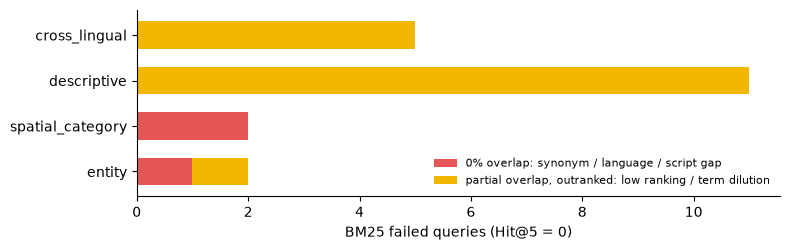

In [19]:
with pd.option_context("display.max_colwidth", 95):
    display(fails[["query_id", "query", "query_tokens", "matched_tokens", "missing_tokens", "overlap",
                   "first_rel_rank", "class"]].round(2))
    display(fails[["query_id", "relevant_example", "bm25_top1"]])

fig, ax = plt.subplots(figsize=(8, 2.6))
counts = fails.groupby(["type", "class"]).size().unstack(fill_value=0).reindex(TYPE_ORDER).fillna(0)
counts.plot.barh(stacked=True, ax=ax, color=["#e45756", "#f2b701"], width=0.6)
ax.set_xlabel("BM25 failed queries (Hit@5 = 0)")
ax.set_ylabel("")
ax.legend(frameon=False, fontsize=8, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**Concrete patterns in the failure table:**

| pattern | example | what is missing |
|---|---|---|
| **Feature wording** | *bežičnim internetom* (7 queries) | the documents say *WiFi* / *wireless internet*; the inflected query form is not even lemmatized |
| **City not indexed** | *kafić … u Mostaru*: overlap 0.8, but the relevant café is at rank 51 | *mostar* is not in that café's `nlp_text`, so it ties with every other café that has takeaway and air conditioning |
| **Synonym / derivation** | *frizer* vs *frizerski salon*; *autoplinom* vs *autoplin / LPG* | a model that knows these words are related |
| **Script** | *музеј у Бањој Луци* | the relevant POI says *Muzej … museum / muzej*; one transliteration step would match it |
| **Diacritics** | *dzamija kalesija* | the relevant POI is at rank 10 because *dzamija ≠ džamija*; *Dzamija Rogatica* wins on the exact spelling |

**The BM25 top-1 column shows the typical wrong answer:** a POI whose **name** contains the city or the preposition (*Univerzitet u Zenici*, *Kantonalni sud u Sarajevu*). It wins on the location words alone and ignores the actual need.

**What this means for the next phase:** most failures are **meaning gaps**, not spelling mistakes. The query and the POI describe the same thing in different words, languages or scripts (*bežični internet ≈ WiFi*, *frizer ≈ frizerski salon ≈ hairdresser*, *музеј ≈ muzej ≈ museum*).

A multilingual sentence-embedding model maps such phrasings to nearby vectors. That makes it the natural next step, alongside cheap fixes that BM25 can use too (transliteration, diacritic folding).

### 5.4 Ablation: what do the preserved prepositions cost in a pure lexical index?

The local explanations in 5.1 already showed something unexpected:
- in `dev-ent-01`, the token **`u`** and the bigram **`u mostar`** provided 81% of the TF-IDF score of the wrong top-1;
- in `dev-des-01`, `u` provided the largest single BM25 contribution.

The reason is that in our corpus *u* is **rare**: it occurs in only ~290 POIs, mostly in names, aliases and addresses (*Univerzitet **u** Banjoj Luci*, *sud **u** Mostaru*). Its IDF (≈ 5.0) is therefore *higher* than that of category words such as *crkva* (≈ 4.1) or *kafić* (≈ 4.0).

To measure the effect, we re-run the evaluation with the preserved words removed **from the query only**. The index stays unchanged, and so do the preserved words' role and availability for a future spatial query parser.

In [20]:
def search_no_prep(query, model, lat=None, lon=None, radius_km=None):
    q_tokens = [t for t in preprocess(query) if t not in PRESERVE]
    scores = score_all(model, q_tokens)
    mask = scores > 0
    if lat is not None and lon is not None and radius_km is not None:
        mask &= haversine_km(lat, lon) <= radius_km
    cand = np.flatnonzero(mask)
    return cand[np.argsort(-scores[cand], kind="stable")]

abl = []
for q in dev:
    rel = set(q["expected_ids"])
    for m in MODELS:
        ranked = IDS[search_no_prep(q["query"], m, q["lat"], q["lon"], q["radius_km"])].tolist()
        abl.append({"type": q["type"], "model": m, "Hit@5": hit_at_k(ranked, rel, 5), "P@5": precision_at_k(ranked, rel, 5),
                    "MRR": reciprocal_rank(ranked, rel), "NDCG@10": ndcg_at_k(ranked, rel, 10)})
abl = pd.DataFrame(abl)
abl["model"] = pd.Categorical(abl["model"], MODELS, ordered=True)

cols = ["Hit@5", "P@5", "MRR", "NDCG@10"]
cmp_overall = pd.concat({"with prepositions": overall[cols],
                         "prepositions dropped from query": abl.groupby("model", observed=True)[cols].mean()}, axis=1)
display(cmp_overall.round(3))
cmp_type = pd.concat({"with": res.groupby(["type", "model"], observed=True)["NDCG@10"].mean(),
                      "dropped": abl.groupby(["type", "model"], observed=True)["NDCG@10"].mean()}, axis=1)
cmp_type["delta"] = cmp_type["dropped"] - cmp_type["with"]
print("NDCG@10 per type:")
display(cmp_type.reindex(TYPE_ORDER, level=0).unstack("model").round(3))

with prepositions                       prepositions dropped from query                      
                   Hit@5    P@5    MRR NDCG@10                           Hit@5    P@5    MRR NDCG@10
model                                                                                               
BoW                 0.40  0.268  0.361   0.378                            0.46  0.292  0.400   0.406
TF-IDF              0.48  0.268  0.406   0.413                            0.52  0.308  0.436   0.453
BM25                0.60  0.292  0.550   0.528                            0.60  0.328  0.568   0.562

NDCG@10 per type:


with               dropped                delta              
model               BoW TF-IDF   BM25     BoW TF-IDF   BM25    BoW TF-IDF   BM25
type                                                                            
entity            0.377  0.517  0.769   0.416  0.531  0.783  0.040  0.013  0.013
spatial_category  0.844  0.794  0.782   0.865  0.865  0.864  0.021  0.071  0.082
descriptive       0.000  0.000  0.033   0.042  0.041  0.047  0.042  0.041  0.014
cross_lingual     0.074  0.125  0.346   0.074  0.154  0.354  0.000  0.029  0.008

**Dropping the prepositions from the query improves every model on almost every metric:**

| | NDCG@10 with | NDCG@10 without | gain |
|---|---|---|---|
| BoW | 0.371 | 0.399 | +0.03 |
| TF-IDF | 0.393 | 0.428 | +0.04 |
| BM25 | 0.473 | **0.505** | +0.03 |

- **The biggest gains are on spatial_category for TF-IDF and BM25** (+0.07 and +0.08). After the ablation, all three models perform equally there (0.86–0.87). The earlier "BoW beats BM25 on spatial" result was therefore entirely an artefact of the high-IDF *u*. BoW has no IDF and was simply less affected.
- **Cross-lingual does not change at all:** those failures are about meaning and script, not prepositions.

**Recommendation.** Keep the spatial prepositions in the pipeline, as the requirements say, because they carry real intent (*kod*, *blizu*, *near*). But in the next phase they should be **consumed by a query parser** that turns *"kafić **kod** Katedrale"* into a spatial constraint. They should not be matched as bag-of-words terms.

**Caveat.** This ablation is a diagnostic measured on dev. The final configuration should still be confirmed once on the untouched test split.

## 6. Conclusions & Next Steps

### Results summary (dev, 50 queries)

| | Hit@5 | MRR | NDCG@10 | strongest on | weakest on |
|---|---|---|---|---|---|
| BoW | 0.40 | 0.36 | 0.37 | spatial_category (no IDF, so the preposition hurts it least) | entity |
| TF-IDF | 0.46 | 0.39 | 0.39 | entity (bigrams, IDF) | cross_lingual |
| **BM25** | **0.54** | **0.49** | **0.47** | **entity (Hit@5 0.87, MRR 0.71)** | descriptive, cross_lingual |

**BM25 is our Demo 1 baseline.** It wins overall and dominates entity search, which is what users do most often with a POI search box.

### What the NLP pipeline contributed

- **Lemmatization:**
  - BHS inflection is normalized (*apoteku, apoteke → apoteka*; *Sarajevu → sarajevo*);
  - two dictionary errors are corrected (*pekara*, *luka*).
- **The custom stopword list:**
  - removed template noise (*address, also known as, m, bb*) and query filler;
  - no stopword leaked into the vocabulary, as verified in 5.2.
- **All processing touched only `nlp_text` and the query text.**
  - Coordinates were used only for the Haversine pre-filter.
  - `id` was used only for evaluation.

### What the XAI analysis showed

1. **Prepositions in a bag-of-words index backfire.**
   - *u* is rare in the corpus, so it gets a higher IDF than category words.
   - POIs whose names contain *"u Sarajevu"* win unrelated queries.
   - Dropping them from the query improves NDCG@10 for all three models (BM25 0.473 → 0.505).
   - **Recommendation:** parse spatial prepositions into constraints instead of matching them as terms.
2. **The city is missing from ~80% of `nlp_text`.** Descriptive queries name a city but carry no coordinates, so they are ranked nationwide and drown in thousands of candidates.
   - **Recommendation:** a gazetteer step that recognizes *u Mostaru / in Bihać / у Зеници* and turns it into the same spatial filter that spatial queries already get.
3. **Most failures are meaning gaps, not spelling mistakes.**
   - Of 23 BM25 failures, 6 have **zero** lexical overlap with any correct POI.
   - Most of the other 17 fail because features and categories are phrased differently in the query and the data.

### Next phase (Demo 2)

| step | fixes | type |
|---|---|---|
| Cyrillic → Latin transliteration + diacritic folding on query and index | Cyrillic queries, *dzamija ≠ džamija*, *djulbasca* | cheap, lexical |
| Gazetteer + spatial query parser (prepositions, city names) | descriptive and English queries with a city, preposition noise | rule-based |
| **Multilingual dense retrieval** (e.g. `bge-m3` / `multilingual-e5`) over `nlp_text` | *bežični internet ≈ WiFi*, *frizer ≈ hairdresser*, *museum ≈ muzej* | semantic |
| **Hybrid BM25 + dense** with Reciprocal Rank Fusion | keeps BM25's entity precision while adding semantic recall | fusion |

The same `dev_queries.json` and the same metric functions will be reused, so every improvement can be measured against the numbers in this notebook. The test split stays untouched until the final comparison.